<a href="https://colab.research.google.com/github/jysim07070707/data-science-toolkit/blob/main/Tutorial_4_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question 1**

**1.**
No

**2.**
Which rule is violated? The rule that "column headers are values, not variable names" is violated. In a tidy dataset, each column should represent a single variable, but here the subject names (Math, Science, English) are used as column headers instead of values under a Subject column, meaning multiple measurements for a student are spread across columns.


**3.**

In [1]:
import pandas as pd

# Create original dataset
data_q1 = {
    "Student": ["Ali", "Sara", "John"],
    "Math": [75, 88, 65],
    "Science": [80, 91, 70],
    "English": [72, 85, 68]
}
df_q1 = pd.DataFrame(data_q1)

# Reshape using melt
tidy_df_q1 = df_q1.melt(
    id_vars=["Student"],
    var_name="Subject",
    value_name="Score"
)

print(tidy_df_q1)


  Student  Subject  Score
0     Ali     Math     75
1    Sara     Math     88
2    John     Math     65
3     Ali  Science     80
4    Sara  Science     91
5    John  Science     70
6     Ali  English     72
7    Sara  English     85
8    John  English     68


**Question 2**

**1.**
What is the tidy-data problem? Similar to Question 1, the column headers (Q1_Sales, Q2_Sales, Q3_Sales, Q4_Sales) represent values of a variable (Quarter) rather than variable names. Multiple columns store values of the same variable (Sales) across different quarters.

In [6]:
import pandas as pd

# Create original dataset
data_q2 = {
    "Country": ["Malaysia", "Thailand", "Indonesia"],
    "Q1_Sales": [12000, 10000, 14000],
    "Q2_Sales": [15000, 11000, 12500],
    "Q3_Sales": [14000, 13000, 15000],
    "Q4_Sales": [18000, 16000, 17000]
}
df_q2 = pd.DataFrame(data_q2)

# Reshape using melt
tidy_df_q2 = df_q2.melt(
    id_vars=["Country"],
    var_name="Quarter",
    value_name="Sales"
)

# Remove '_Sales' suffix from Quarter values
tidy_df_q2["Quarter"] = tidy_df_q2["Quarter"].str.replace("_Sales", "")

# Sort by Country (and optionally by Quarter) so it reads country by country
tidy_df_q2 = tidy_df_q2.sort_values(by=["Country", "Quarter"]).reset_index(drop=True)

print(tidy_df_q2)



      Country Quarter  Sales
0   Indonesia      Q1  14000
1   Indonesia      Q2  12500
2   Indonesia      Q3  15000
3   Indonesia      Q4  17000
4    Malaysia      Q1  12000
5    Malaysia      Q2  15000
6    Malaysia      Q3  14000
7    Malaysia      Q4  18000
8    Thailand      Q1  10000
9    Thailand      Q2  11000
10   Thailand      Q3  13000
11   Thailand      Q4  16000


**Question 3**

1. Average study time: 4.833333333333333 hours
2. Average score: 71.66666666666667
3. Student with the highest score: F
4. Student who studied the most: F
5. Correlation coefficient: 1.00
   Answer: Yes, studying more hours appears to be strongly associated with a higher score (positive correlation).


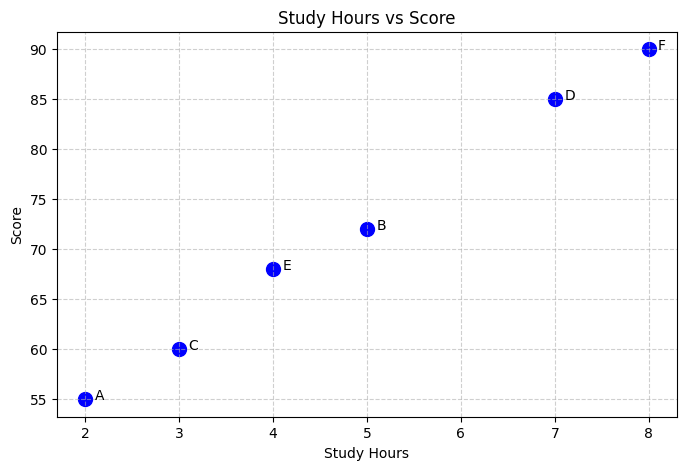

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
data = {
    "Student": ["A", "B", "C", "D", "E", "F"],
    "Study_Hours": [2, 5, 3, 7, 4, 8],
    "Score": [55, 72, 60, 85, 68, 90]
}
df = pd.DataFrame(data)

# 1. What is the average study time?
avg_study_time = df["Study_Hours"].mean()
print(f"1. Average study time: {avg_study_time} hours")

# 2. What is the average score?
avg_score = df["Score"].mean()
print(f"2. Average score: {avg_score}")

# 3. Which student obtained the highest score?
top_score_student = df.loc[df["Score"].idxmax(), "Student"]
print(f"3. Student with the highest score: {top_score_student}")

# 4. Which student studied the most?
most_studious_student = df.loc[df["Study_Hours"].idxmax(), "Student"]
print(f"4. Student who studied the most: {most_studious_student}")

# 5. Association analysis
correlation = df["Study_Hours"].corr(df["Score"])
print(f"5. Correlation coefficient: {correlation:.2f}")
print("   Answer: Yes, studying more hours appears to be strongly associated with a higher score (positive correlation).")

# 6. Create a scatter plot of Study_Hours vs Score
plt.figure(figsize=(8, 5))
plt.scatter(df["Study_Hours"], df["Score"], color="blue", s=100)
for i, row in df.iterrows():
    plt.annotate(row["Student"], (row["Study_Hours"] + 0.1, row["Score"]))

plt.title("Study Hours vs Score")
plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()
